# 3 · The budget regime: truncation turns candidate ORDER into accuracy

*Part 3 of the story. Previously: `02_full_context.ipynb` showed saturation at full context.*

**What this notebook answers.** We re-ran the identical 36 questions with
candidate budgets of **3, 2 and 1**. Same model, same questions, same prompts
for A/B - only the number of candidates shown to C and D changed. This is the
regime where their ordering rule is the only difference that matters.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import elexai.analysis as al

al.scientific_style()
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.width", 220)


run_of = {
    1: al.find_run("cap1"),
    2: al.find_run("cap2"),
    3: al.find_run("cap3"),
    12: al.find_run("skeleton"),
}
caps = [1, 2, 3, 12]
acc = al.accuracy_frame(list(run_of.values()))
acc["cap"] = acc["cap"].astype(int)
answers_by_cap = {cap: al.load_answers(rid) for cap, rid in run_of.items()}
senses = al.load_senses_table().set_index("sense_id")
questions = al.load_questions_table().set_index("question_id")

summary = acc[acc["variant"].isin(["C", "D", "B", "oracle"])].pivot_table(
    index="cap", columns="variant", values="citation_accuracy_excl_trick"
).round(3)
summary

variant,B,C,D,oracle
cap,,,,
1,0.294,0.353,0.529,1.0
2,0.294,0.559,0.676,1.0
3,0.294,0.735,0.824,1.0
12,0.294,1.000,1.000,1.0


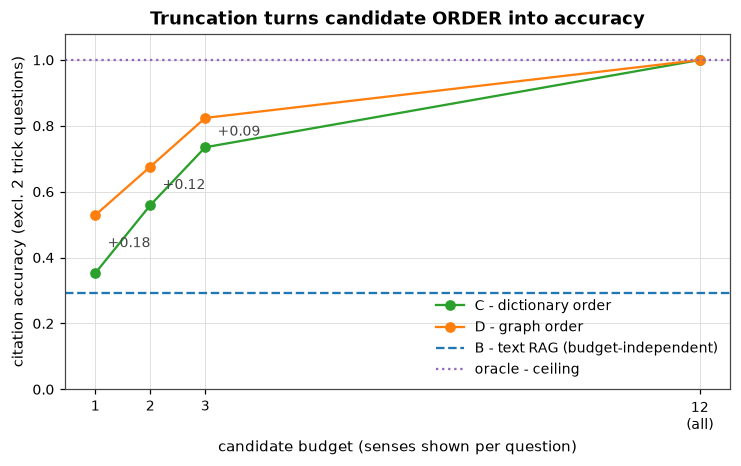

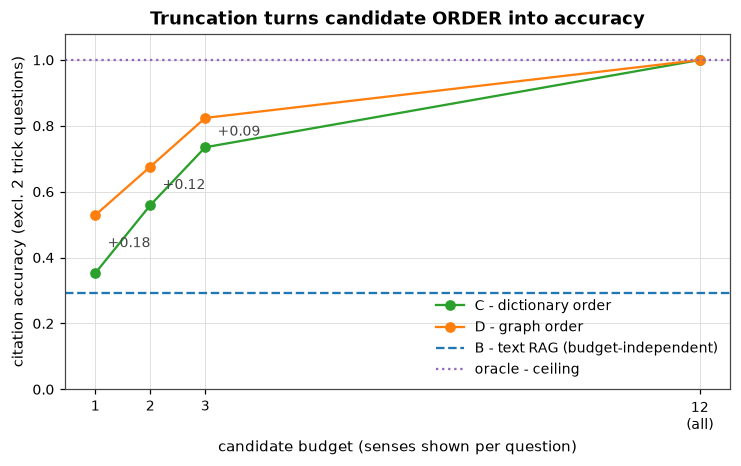

In [2]:
def series(variant, col="citation_accuracy_excl_trick"):
    s = acc[acc["variant"] == variant].set_index("cap")[col]
    return [s[c] for c in caps]

fig, ax = plt.subplots(figsize=(7.8, 4.2))
c_s, d_s = series("C"), series("D")
ax.plot(caps, c_s, "o-", color=al.VARIANT_COLORS["C"], label="C - dictionary order")
ax.plot(caps, d_s, "o-", color=al.VARIANT_COLORS["D"], label="D - graph order")
ax.axhline(series("B")[0], ls="--", color=al.VARIANT_COLORS["B"], label="B - text RAG (budget-independent)")
ax.axhline(series("oracle")[0], ls=":", color=al.VARIANT_COLORS["oracle"], label="oracle - ceiling")
for i, cap in enumerate(caps):
    if d_s[i] > c_s[i] + 1e-9:
        ax.annotate(
            f"+{d_s[i] - c_s[i]:.2f}", (cap, (c_s[i] + d_s[i]) / 2),
            textcoords="offset points", xytext=(8, -2), fontsize=9, color="#444444",
        )
ax.set_xticks(caps, ["1", "2", "3", "12\n(all)"])
ax.set_xlabel("candidate budget (senses shown per question)")
ax.set_ylabel("citation accuracy (excl. 2 trick questions)")
ax.set_ylim(0, 1.08)
ax.set_title("Truncation turns candidate ORDER into accuracy")
ax.legend(loc="lower right")
al.save_figure(fig, "03_budget_curve")
fig

> **Reading the chart.** With everything visible, C and D are identical (100 %).
> As the budget shrinks, both fall - but D falls more slowly:
> **+0.09 at budget 3, +0.12 at budget 2, +0.18 at budget 1**.
> B is flat (its context size never changes) and the oracle ceiling stays at
> 100 %: the drop is purely about *which* candidates make it onto the table.

> **Takeaway (budget crossover).** Structured ordering only pays off when the
> context budget is smaller than the candidate set - and the smaller the
> budget, the larger the gain. With everything visible, building the graph
> would have been wasted effort.

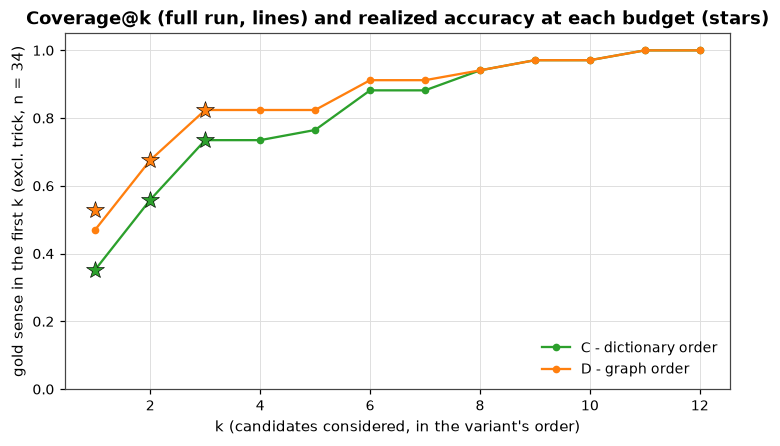

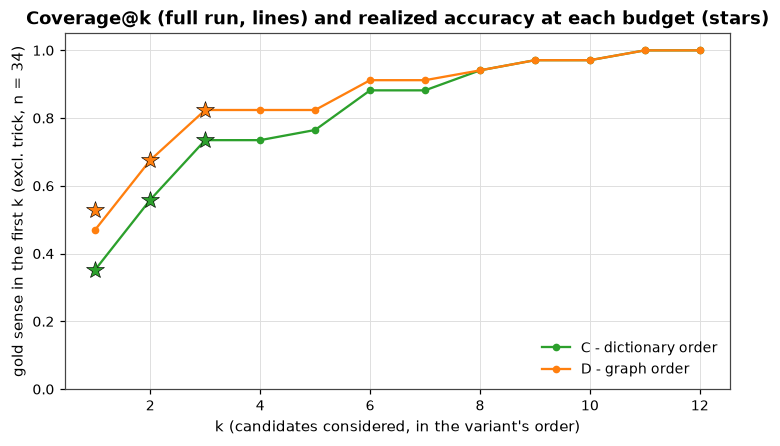

In [3]:
cov = al.coverage_frame([run_of[12]], scope="excl_trick")

fig, ax = plt.subplots(figsize=(7.8, 4.2))
for v, label in [("C", "C - dictionary order"), ("D", "D - graph order")]:
    sub = cov[cov["variant"] == v].sort_values("k")
    ax.plot(sub["k"], sub["coverage"], "o-", ms=4, color=al.VARIANT_COLORS[v], label=label)
for cap in [1, 2, 3]:
    for v in ["C", "D"]:
        val = float(acc[(acc["cap"] == cap) & (acc["variant"] == v)]["citation_accuracy_excl_trick"].iloc[0])
        ax.plot([cap], [val], marker="*", ms=12, color=al.VARIANT_COLORS[v], mec="black", mew=0.4, zorder=5)
ax.set_xlabel("k (candidates considered, in the variant's order)")
ax.set_ylabel("gold sense in the first k (excl. trick, n = 34)")
ax.set_ylim(0, 1.05)
ax.set_title("Coverage@k (full run, lines) and realized accuracy at each budget (stars)")
ax.legend(loc="lower right")
al.save_figure(fig, "03_coverage_curves")
fig

> **Reading the chart.** The lines are the *potential*: how often the gold
> sense sits within the first k candidates under each ordering (C's order is
> the dictionary's; D's is the graph's ranking, logged for all candidates).
> D's curve lies above C's everywhere. The stars are what actually happened in
> the budget runs - they sit essentially **on the curves**, because the model's
> composition was error-free once the gold was shown (C: 0 composition errors
> at every budget; D: only the trick items). **Under truncation, coverage IS
> accuracy.**

,budget,D right / C wrong,C right / D wrong,McNemar p
0,1,7,1,0.070
1,2,4,0,0.125
2,3,3,0,0.250
3,12,0,0,1.000


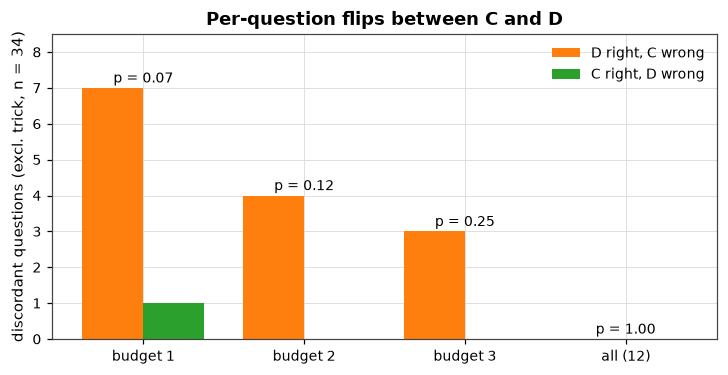

In [4]:
rows = []
for cap in caps:
    m = al.correctness_matrix(answers_by_cap[cap], variants=("C", "D"))
    b = int((m["D"] & ~m["C"]).sum())
    c = int((m["C"] & ~m["D"]).sum())
    rows.append({"budget": cap, "D right / C wrong": b, "C right / D wrong": c, "McNemar p": round(al.mcnemar_exact(b, c), 3)})
disc = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7.8, 3.6))
x = np.arange(len(disc))
w = 0.38
ax.bar(x - w / 2, disc["D right / C wrong"], w, color=al.VARIANT_COLORS["D"], label="D right, C wrong")
ax.bar(x + w / 2, disc["C right / D wrong"], w, color=al.VARIANT_COLORS["C"], label="C right, D wrong")
for i, r in disc.iterrows():
    ax.text(i, max(r["D right / C wrong"], r["C right / D wrong"]) + 0.15, f"p = {r['McNemar p']:.2f}", ha="center", fontsize=9)
ax.set_xticks(x, ["budget 1", "budget 2", "budget 3", "all (12)"])
ax.set_ylabel("discordant questions (excl. trick, n = 34)")
ax.set_ylim(0, 8.5)
ax.set_title("Per-question flips between C and D")
ax.legend()
al.save_figure(fig, "03_discordant")
disc

> **Reading the chart.** D's advantage is a *superset* of C's: at budgets 3 and 2
> D wins 3-4 questions and loses none; at budget 1 it wins 7 and loses 1.
> The exact McNemar p-values (0.07-0.25) remind us that with 34 questions a
> consistent +3..7-question shift is *signal, not proof* - the budget curve is
> the stronger evidence because the effect grows monotonically with truncation.

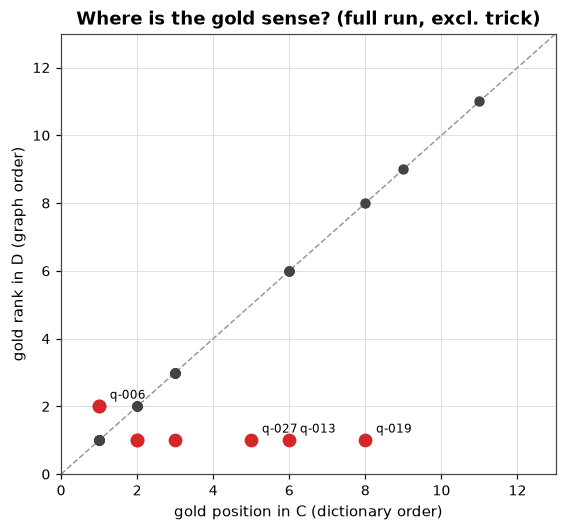

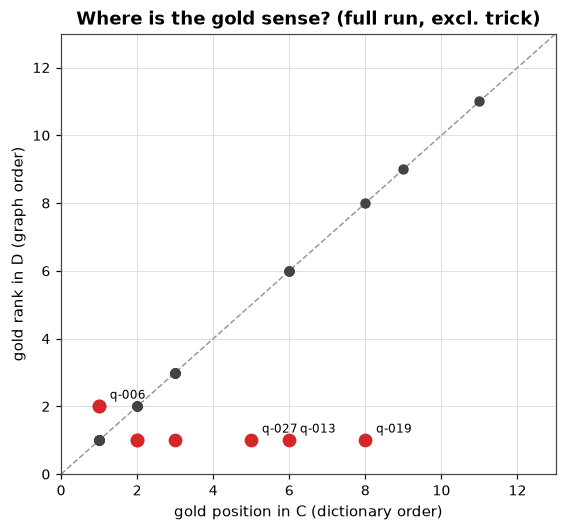

In [5]:
c_full = al.load_answers(run_of[12])
c_tab = c_full[c_full["variant"] == "C"].set_index("question_id")
d_tab = c_full[c_full["variant"] == "D"].set_index("question_id")

pts = []
for qid in c_tab.index:
    if bool(c_tab.loc[qid, "is_trick"]):
        continue
    gold = c_tab.loc[qid, "gold_sense_id"]
    shown = list(c_tab.loc[qid, "shown_ids"] or [])
    c_pos = shown.index(gold) + 1 if gold in shown else None
    d_rank = d_tab.loc[qid, "gold_rank"]
    if c_pos is None or pd.isna(d_rank):
        continue
    pts.append((qid, c_pos, int(d_rank)))

fig, ax = plt.subplots(figsize=(5.8, 5.2))
ax.plot([0, 13], [0, 13], ls="--", color="#999999", lw=1)
for _qid, cp, dr in pts:
    ax.scatter([cp], [dr], s=34, color="#444444", zorder=3)
flip = sorted(qid for qid, cp, dr in pts if cp != dr)
label = {"q-006", "q-013", "q-019", "q-027"}
for qid, cp, dr in sorted(pts, key=lambda p: p[0]):
    if qid in flip:
        ax.scatter([cp], [dr], s=64, color="#d62728", zorder=4)
        if qid in label:
            ax.annotate(qid, (cp, dr), textcoords="offset points", xytext=(7, 5), fontsize=8)
ax.set_xlabel("gold position in C (dictionary order)")
ax.set_ylabel("gold rank in D (graph order)")
ax.set_title("Where is the gold sense? (full run, excl. trick)")
ax.set_xlim(0, 13)
ax.set_ylim(0, 13)
al.save_figure(fig, "03_gold_positions")
fig

> **Reading the chart.** Points **below the diagonal** are questions where the
> graph order finds the gold earlier than the dictionary does; points above are
> the reverse. Red points differ between the two orders; the four labelled
> ones (q-006, q-013, q-019, q-027) are discussed below and in the table that
> follows. D keeps the gold within rank 3 for almost everything; C's dictionary
> order scatters the gold across the whole list. The caps (1/2/3) cut into
> exactly this difference.

In [6]:
flip_rows = []
for cap in [1, 2, 3]:
    m = al.correctness_matrix(answers_by_cap[cap], variants=("C", "D"))
    for qid in m.index[m["D"] & ~m["C"]]:
        flip_rows.append({
            "budget": cap,
            "question": qid,
            "lemma": questions.loc[qid, "lemma"],
            "gold sense": senses.loc[questions.loc[qid, "gold_sense_id"], "definition"][:60],
        })
pd.DataFrame(flip_rows)

,budget,question,lemma,gold sense
0,1,q-001,kos,"del celote | del snovi, predmeta ali živila, navadno ločen o"
1,1,q-013,kolo,del vozila
2,1,q-019,srce,"osrednji, najpomembnejši del"
3,1,q-020,kos,"ptica | pogosta ptica pevka, katere samec je črne barve z ru"
4,1,q-023,mesec,o obdobju tridesetih dni
5,1,q-027,kos,"izdelek; primerek | posamezen izdelek ali predmet, ki je del"
6,1,q-036,revščina,o stanju finančnega pomanjkanja
7,2,q-013,kolo,del vozila
8,2,q-019,srce,"osrednji, najpomembnejši del"
9,2,q-020,kos,"ptica | pogosta ptica pevka, katere samec je črne barve z ru"


## The decisive questions: why D wins

Three questions flip at *every* budget (1, 2 and 3):
`q-013` (*kolo*), `q-019` (*srce*), `q-027` (*kos*). Below: the sentence, what
C shows in its first 3 slots, what D shows, and which neighbourhood features
pushed the gold sense up.

In [7]:
for qid in ["q-013", "q-019", "q-027"]:
    print("=" * 74)
    print(qid, "|", questions.loc[qid, "question"])
    gold = c_tab.loc[qid, "gold_sense_id"]
    print("gold:", gold, "-", senses.loc[gold, "definition"][:80])
    print("C first 3:", [(s, senses.loc[s, "definition"][:42]) for s in c_tab.loc[qid, "shown_ids"][:3]])
    print("D first 3:", [(s, senses.loc[s, "definition"][:42]) for s in d_tab.loc[qid, "ranked_ids"][:3]])
    feats = {f["sense_id"]: f for f in (d_tab.loc[qid, "ranked_features"] or [])}
    gf = feats.get(gold, {})
    print("D matched for gold:", {"collocations": gf.get("matched_collocations"), "definition": gf.get("matched_definition")})

q-013 | Kateri pomen besede »kolo« je uporabljen v podanem stavku?
gold: 16252265 - del vozila
C first 3: [('16252263', 'prevozno sredstvo'), ('16253615', 'o tekmovanju'), ('16277229', 'potek dogodkov | neustavljiv potek zgodovi')]
D first 3: [('16252265', 'del vozila'), ('16252263', 'prevozno sredstvo'), ('16253615', 'o tekmovanju')]
D matched for gold: {'collocations': ['rezervno'], 'definition': []}
q-019 | Kateri pomen besede »srce« je uporabljen v podanem stavku?
gold: 16268672 - osrednji, najpomembnejši del
C first 3: [('8181071', 'prestrašiti se | če komu pade srce v hlače'), ('8183986', 'o občutku prizadetosti | če koga boli srce'), ('16268669', 'organ')]
D first 3: [('16268672', 'osrednji, najpomembnejši del'), ('8181071', 'prestrašiti se | če komu pade srce v hlače'), ('8183986', 'o občutku prizadetosti | če koga boli srce')]
D matched for gold: {'collocations': ['mesta'], 'definition': []}
q-027 | Kateri pomen besede »kos« je uporabljen v podanem stavku?
gold: 16283273 - izd

> **What we see.** The pattern is identical in all three cases: the sentence
> contains a word that belongs to the *gold sense's typical collocations* -
> "rezervno" (spare wheel), "mesta" (heart of the city), "evrov" (per piece) -
> while the dictionary's first slots are occupied by the word's more frequent
> senses. The graph order simply knows those collocations; the dictionary
> order ignores the sentence. **This is the mechanism behind every D win.**

> **Takeaway.** The gain is not "the graph understands language" - it is that
> structured neighbourhoods (typical collocations, synonyms, synsets) provide
> a second, non-embedding retrieval signal that can rescue senses the text
> alone buries.

In [8]:
miss_rows = []
for cap in [1, 2, 3]:
    d = answers_by_cap[cap]
    d = d[(d["variant"] == "D") & (~d["is_trick"])]
    misses = d[d["gold_rank"].notna() & (d["gold_rank"] > cap)]
    for _, r in misses.iterrows():
        miss_rows.append({
            "budget": cap,
            "question": r["question_id"],
            "lemma": r["lemma"],
            "gold rank": int(r["gold_rank"]),
            "gold sense": senses.loc[r["gold_sense_id"], "definition"][:55],
        })
pd.DataFrame(miss_rows).sort_values(["budget", "gold rank"])

,budget,question,lemma,gold rank,gold sense
0,1,q-002,list,2,del rastline
1,1,q-003,greda,2,"v gradbeništvu | dolg, navadno vodoravno nameščen konst"
2,1,q-004,obraz,2,del telesa
3,1,q-006,pero,2,pisalo
4,1,q-007,pero,2,del telesa ptic
6,1,q-010,jabolko,3,"sadež | sadež jablane okrogle oblike z rdečo, rumeno al"
8,1,q-015,mesec,3,Zemljin satelit
10,1,q-018,srce,3,organ
12,1,q-025,list,3,riba
14,1,q-028,most,3,o sodelovanju | povezava


> **What we see.** Even D misses 6-9 questions per budget. Their profile is
> consistent: the gold sense is a **late, specific sense** (position 5-11 in
> the dictionary) whose sentence shares **no vocabulary** with the sense's
> definition, collocations or synset words - e.g. *pero* = "spring" (q-024),
> *jabolko* = "apple tree" (q-026), *srce* = "drawn shape" (q-029). The ranking
> can only use overlap; no overlap, no signal.

> **Takeaway (honest limit).** The graph ranking fixes the *buried but
> lexically reachable* senses. The remaining failures need semantic scoring
> (definitions vs sentence meaning, not word overlap) - a concrete next step,
> not a solved problem.

## Counter-cases and honesty

- **q-006** (*pero* = "pisalo") is the one question where **C beats D** at
  budget 1: the dictionary-first sense happened to be correct, while D's
  ranking put the bird-feather sense first. A reminder that "most frequent
  first" is a strong baseline.
- **q-005 / q-016** are flagged `trick` and excluded - at small budgets C
  "accidentally" wins them (the flawed candidate no longer fits), which is a
  property of the flaw, not of the method.
- **C vs D contexts are not byte-identical** (see `docs/DECISIONS.md` D-024):
  the graph path prints synonym/collocation lists sorted alphabetically, so the
  *content* of a block can differ slightly between C and D. The decisive
  mechanism here is *which* candidates are shown (coverage), which is unaffected.

**Takeaway for practice.** If your retrieval can show everything, stop there.
If you must truncate (token budget, latency, cost), rank candidates with
structured links - typical collocations, synonyms, knowledge-graph edges -
before or instead of a second similarity pass: coverage, not eloquence,
is what the budget converts into accuracy.